In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
print(mpl.get_backend())
import sys; print(sys.executable)


module://matplotlib_inline.backend_inline
C:\Users\maria\anaconda3\envs\remoteSensing\python.exe


In [ ]:
import matplotlib.pyplot as plt; fig, ax = plt.subplots(); ax.scatter([1],[2]); fig.savefig('test.png'); print('ok!')

In [3]:
import matplotlib.pyplot as plt
print("pyplot ok")

pyplot ok


In [ ]:
fig, ax = plt.subplots()
print("figure ok")

figure ok


In [ ]:
ax.scatter([1], [2])
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib
print(matplotlib.get_backend())
fig, ax = plt.subplots()
ax.scatter([1], [2])
fig.savefig("test.png")
print("saved")
plt.close(fig)   # closing it stops the inline backend from displaying it

module://matplotlib_inline.backend_inline


In [1]:
import matplotlib
print(matplotlib.get_cachedir())

C:\Users\maria\.matplotlib


In [ ]:
lv=np.linspace(-1,1,21); zv=np.zeros(21); ov=np.ones(21)
x=np.hstack([np.sin(np.linspace(0,2*np.pi,81)),zv,lv,lv,lv,ov,-ov])
y=np.hstack([np.cos(np.linspace(0,2*np.pi,81)),lv,zv,ov,-ov,lv,lv])
z=np.ones(207)

plt.scatter([1, ], [2, ])
plt.show()
# plt.scatter(x,y)

In [ ]:
phi = np.deg2rad(0)
theta = np.deg2rad(90)
x0 = 0
y0 = 0
alph_x = 1.0
alph_y = 1.0

cos_phi = np.cos(phi)
sin_phi = np.sin(phi)


In [ ]:
alpha = np.deg2rad(0)
beta = np.deg2rad(20)
gamma = np.deg2rad(10)
t_vec = np.array([1, 0, 0]).reshape((3,1))


In [ ]:

def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0,  0],
                     [0, c, -s],
                     [0, s,  c]])

def Ry(b):
    c, s = np.cos(b), np.sin(b)
    return np.array([[ c, 0, s],
                     [ 0, 1, 0],
                     [-s, 0, c]])

def Rz(g):
    c, s = np.cos(g), np.sin(g)
    return np.array([[c, -s, 0],
                     [s,  c, 0],
                     [0,  0, 1]])

R_c = Rx(alpha) @ Ry(beta) @ Rz(gamma)
print(R_c)



In [ ]:
X_c = np.hstack((
    np.vstack((R_c, np.zeros(3))),
    np.vstack((- R_c @ t_vec, 1))
))
print(X_c)

In [ ]:
T = np.array([
    [1, 0, x0],
    [0, 1, y0],
    [0, 0, 1]
])
R = np.array([
    [cos_phi, sin_phi, 0],
    [-sin_phi, cos_phi, 0],
    [0, 0, 1]
])
D = np.identity(3)
D[0,0] = alph_x
D[1,1] = alph_y
S = np.array([
    [1, - 1 / np.tan(theta), 0],
    [0, 1 / np.sin(theta), 0],
    [0, 0, 1]
])

K = T @ R @ D @ S
print(K)

In [ ]:
K_with_0 = np.hstack(
    (K, 
     np.zeros((3, 1))
    )
)
print(K_with_0)

In [ ]:
X_whatever = K_with_0 @ X_c

In [ ]:
values_projected_x_list = []
values_projected_y_list = []
for x_value, y_value, z_value in zip(x, y, z):
    X_i = X_whatever @ np.array([x_value, y_value, z_value, 1]).reshape((4,1))
    
    value_projected_x = X_i[0] / X_i[2]
    value_projected_y = X_i[1] / X_i[2]
    values_projected_x_list.append(value_projected_x)
    values_projected_y_list.append(value_projected_y)
    


In [ ]:
color_r = np.linspace(0, 1.0, 207)
plt.scatter(np.array(values_projected_x_list), np.array(values_projected_y_list), c=np.array(values_projected_y_list), cmap="coolwarm")

In [3]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt



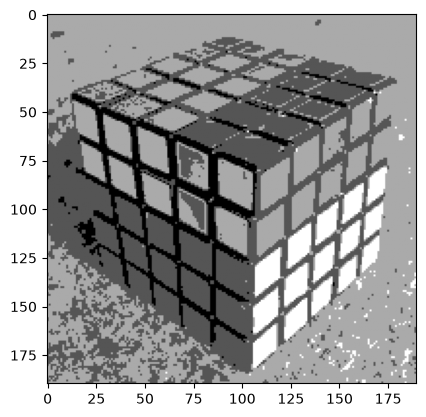

In [10]:
img = np.mean(plt.imread('cube.png'), axis=2)

quant_num = 4
img = np.round(img * (quant_num - 1)) / (quant_num - 1)

plt.figure()
plt.imshow(img, cmap='gray')

In [5]:
print(img)

[[0.52026147 0.52418303 0.53464055 ... 0.5934641  0.62222224 0.63398695]
 [0.54509807 0.53594774 0.5424836  ... 0.606536   0.62352943 0.6169935 ]
 [0.5568628  0.551634   0.5647059  ... 0.60915035 0.6130719  0.5882353 ]
 ...
 [0.34640524 0.5385621  0.47712418 ... 0.75163394 0.6797386  0.7163399 ]
 [0.46535948 0.48235294 0.61568624 ... 0.74379086 0.6653595  0.7176471 ]
 [0.38169935 0.51633984 0.6130719  ... 0.6535948  0.7006536  0.7372549 ]]
